# 10 — Attention Visualization
Visualize learned attention coefficients when available from GAT layers.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

PROJECT_ROOT = Path("..").resolve()
edges = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "segment_graph_edges.csv")
mapping = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "road_segment_mapping.csv")


/home/runner/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/runner/.local/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


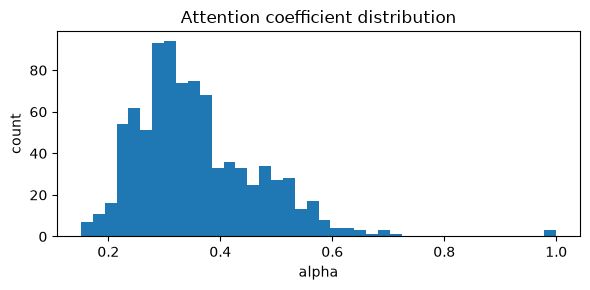

   src  dst     alpha
0  286  286  1.000000
1  262  262  1.000000
2   79   79  1.000000
3  253  253  0.710900
4  249  251  0.691359
5  270  270  0.688255
6  249  249  0.684229
7  204  204  0.663798
8  205  205  0.652393
9  139  139  0.650727


In [2]:
try:
    from torch_geometric.nn import GATConv
    class AttnProbe(torch.nn.Module):
        def __init__(self):
            super().__init__()
            self.conv = GATConv(4, 8, heads=2, dropout=0.0)
        def forward(self, x, edge_index):
            out, (ei, alpha) = self.conv(x, edge_index, return_attention_weights=True)
            return out, ei, alpha

    model = AttnProbe()
    x = torch.randn(len(mapping), 4)
    edge_index = torch.tensor(edges[["src","dst"]].to_numpy().T, dtype=torch.long)
    _, ei, alpha = model(x, edge_index)
    alpha_mean = alpha.mean(dim=1).detach().numpy()

    plt.figure(figsize=(6,3))
    plt.hist(alpha_mean, bins=40)
    plt.title("Attention coefficient distribution")
    plt.xlabel("alpha")
    plt.ylabel("count")
    plt.tight_layout(); plt.show()

    top_idx = np.argsort(-alpha_mean)[:10]
    top_edges = pd.DataFrame({"src": ei[0][top_idx].numpy(), "dst": ei[1][top_idx].numpy(), "alpha": alpha_mean[top_idx]})
    print(top_edges)
except Exception as e:
    print("Attention extraction unavailable in current setup:", e)


## Caution
Attention is a model-internal weighting signal, not guaranteed causal evidence.


In [3]:
print("Compare attention patterns across scenario-conditioned inputs in future iterations.")


Compare attention patterns across scenario-conditioned inputs in future iterations.


## Limitations and next steps
Further calibration with real Bangalore/SUMO data is required.